# Replication: Wang et al. 1998, Fig. 5C/D

**Experiment (REF2, "Numerical simulations"):** stimulate the MNTB model with trains of brief current pulses (1.4 nA, 0.25 ms) at 100, 200, 300 and 400 Hz.

* **Fig. 5C**, control (g_Kv3 = 150 nS): the model follows every pulse up to ~300 Hz; at 400 Hz some pulses fail.
* **Fig. 5D**, Kv3.1 removed (g_Kv3 = 0, mimics 1 mM TEA): spikes still follow at 100–200 Hz, but from ~300 Hz only the first pulse gives a full spike.

Kernel: `ataxia_env`.

In [1]:
import tempfile
import numpy as np
import matplotlib.pyplot as plt
import nest
from pynestml.codegeneration.nest_code_generator_utils import NESTCodeGeneratorUtils

# Pass the file *path*: given the model text instead, NESTML writes
# hh_mntb_kv31_neuron.nestml into this folder and overwrites the existing file.
# Generated C++ code goes to a temporary folder, not into the repo.
module, model = NESTCodeGeneratorUtils.generate_code_for("hh_mntb_kv31_neuron_v2.nestml",
                                                         target_path=tempfile.mkdtemp())


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Apr 14 2026 11:46:17

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Apr 14 2026 11:46:17

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

[14,hh_mntb_kv31_neuron_nestml, WARNING, [36:30;36:42]]: Model contains a call to fixed-timestep functions (``resolution()`` and/or ``steps()``). This restricts the model to being compatible only with fixed-timestep simulators. Consider eliminating ``resolution()`` and ``steps()`` from the model, and using ``timestep()`` instead.


In [2]:
def pulse_train(freq, g_Kv3, n_pulses=10, amp=1400., width=0.25, t_start=100., t_after=None):
    nest.ResetKernel()
    nest.set_verbosity("M_ERROR")
    nest.Install(module)
    nest.resolution = 0.01

    neuron = nest.Create(model, params={"g_Kv3": g_Kv3})

    # pulse times, rounded to the simulation grid
    onsets = t_start + (1000. / freq) * np.arange(n_pulses)
    times = np.round(np.ravel([[t, t + width] for t in onsets]), 2)
    amps = [amp, 0.] * n_pulses
    stim = nest.Create("step_current_generator",
                       params={"amplitude_times": times, "amplitude_values": amps})
    vm = nest.Create("voltmeter", params={"interval": 0.01})

    nest.Connect(stim, neuron, syn_spec={"delay": 0.01})   # default delay would be 1 ms
    nest.Connect(vm, neuron)

    # the first 100 ms let the cell settle at rest before the pulses start;
    # t_after = how long to keep recording after the last pulse (default: one period)
    t_after = 1000. / freq if t_after is None else t_after
    nest.Simulate(round(onsets[-1] + t_after, 2))

    t, V = vm.events["times"], vm.events["V_m"]

    # A pulse "succeeds" if V_m peaks above -10 mV before the next pulse
    # (the failure criterion of REF1, Macica et al. 2003).
    period = 1000. / freq
    n_spikes = sum(V[(t >= t0) & (t < t0 + period)].max() > -10 for t0 in onsets)
    return t, V, n_spikes

IndexError: index 2 is out of bounds for axis 1 with size 2

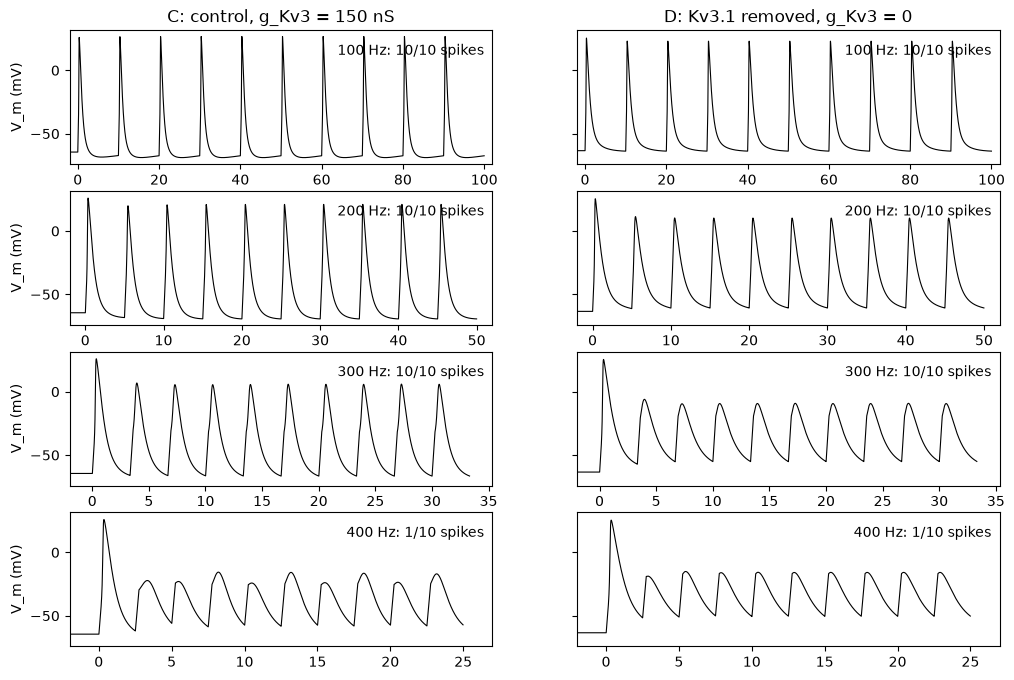

In [10]:
freqs = [100, 200, 300, 400]
conditions = {"C: control, g_Kv3 = 150 nS": 150., "D: Kv3.1 removed, g_Kv3 = 0": 0., "D: Kv3.1 removed, g_Kv3 = 35": 35.}

fig, axes = plt.subplots(len(freqs), 2, figsize=(12, 8), sharey=True)
for col, (title, g) in enumerate(conditions.items()):
    for row, f in enumerate(freqs):
        t, V, n_spikes = pulse_train(f, g)
        ax = axes[row, col]
        ax.plot(t - 100, V, "k", lw=0.8)
        ax.set_xlim(-2, 10 * 1000 / f + 2)
        ax.text(0.98, 0.9, f"{f} Hz: {n_spikes}/10 spikes", transform=ax.transAxes, ha="right", va="top")
        if row == 0:
            ax.set_title(title)
        if col == 0:
            ax.set_ylabel("V_m (mV)")
for ax in axes[-1]:
    ax.set_xlabel("time from first pulse (ms)")
plt.tight_layout()
plt.show()

IndexError: index 2 is out of bounds for axis 1 with size 2

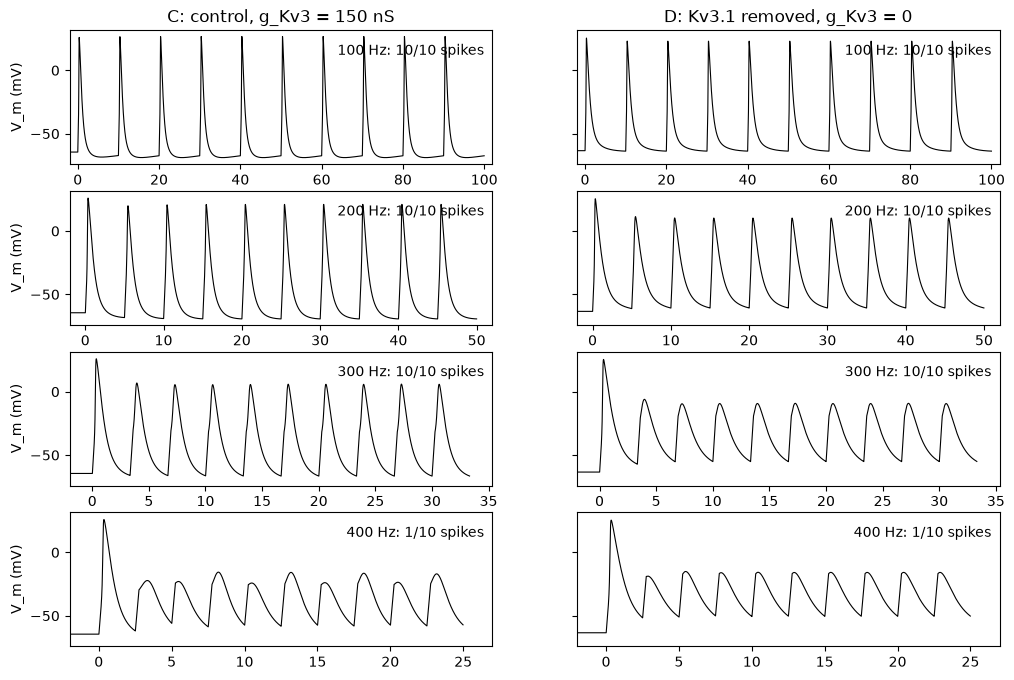

In [ ]:
freqs = [100, 200, 300, 400]
conditions = {"C: control, g_Kv3 = 150 nS": 150., "D: Kv3.1 removed, g_Kv3 = 0": 35.}

fig, axes = plt.subplots(len(freqs), 2, figsize=(12, 8), sharey=True)
for col, (title, g) in enumerate(conditions.items()):
    for row, f in enumerate(freqs):
        t, V, n_spikes = pulse_train(f, g)
        ax = axes[row, col]
        ax.plot(t - 100, V, "k", lw=0.8)
        ax.set_xlim(-2, 10 * 1000 / f + 2)
        ax.text(0.98, 0.9, f"{f} Hz: {n_spikes}/10 spikes", transform=ax.transAxes, ha="right", va="top")
        if row == 0:
            ax.set_title(title)
        if col == 0:
            ax.set_ylabel("V_m (mV)")
for ax in axes[-1]:
    ax.set_xlabel("time from first pulse (ms)")
plt.tight_layout()
plt.show()

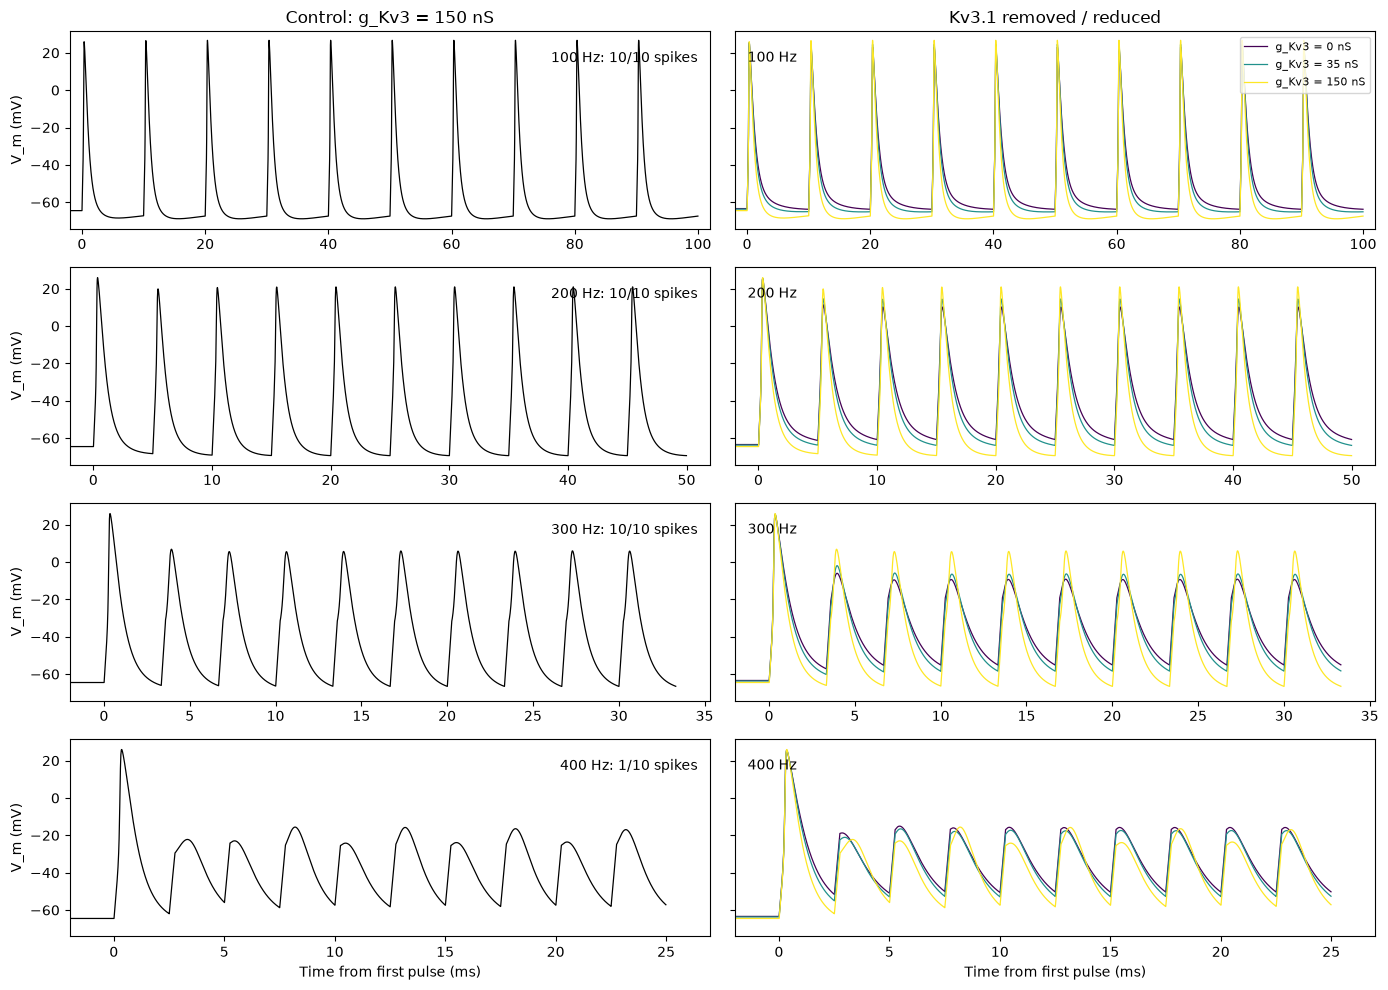

In [13]:
freqs = [100, 200, 300, 400]

g_Kv3_values = [0, 35, 150]

fig, axes = plt.subplots(len(freqs), 2, figsize=(14, 10), sharey=True)

# Colors for the different g_Kv3 values
colors = plt.cm.viridis(np.linspace(0, 1, len(g_Kv3_values)))

for row, f in enumerate(freqs):

    # LEFT: Control condition
    t, V, n_spikes = pulse_train(f, 150)

    ax = axes[row, 0]
    ax.plot(t - 100, V, "k", lw=0.9)
    ax.set_xlim(-2, 10 * 1000 / f + 2)
    ax.text(0.98, 0.9, f"{f} Hz: {n_spikes}/10 spikes",
            transform=ax.transAxes, ha="right", va="top")

    if row == 0:
        ax.set_title("Control: g_Kv3 = 150 nS")

    ax.set_ylabel("V_m (mV)")

    # RIGHT: Multiple Kv3 conductances overlaid
    ax = axes[row, 1]

    for g, color in zip(g_Kv3_values, colors):
        t, V, n_spikes = pulse_train(f, g)

        ax.plot(t - 100, V, color=color, lw=0.9,
                label=f"g_Kv3 = {g} nS")

    ax.set_xlim(-2, 10 * 1000 / f + 2)

    if row == 0:
        ax.set_title("Kv3.1 removed / reduced")
        ax.legend(fontsize=8, loc="upper right")

    ax.text(0.02, 0.9, f"{f} Hz",
            transform=ax.transAxes, ha="left", va="top")

for ax in axes[-1]:
    ax.set_xlabel("Time from first pulse (ms)")

plt.tight_layout()
plt.show()

## Version 2: same stimulus protocol as the paper

The data are produced and laid out the way Wang et al. did for Fig. 5C/D, on normal axes:
* **Same train length at every frequency, about 100 ms**, so the number of pulses grows with frequency: 10 at 100 Hz, 20 at 200 Hz, 30 at 300 Hz, 40 at 400 Hz.
* **One shared time axis** for all panels, so the rows can be compared directly.
* A short stretch of baseline before the train and the recovery after it.
* Same pulses as above: 1.4 nA, 0.25 ms.

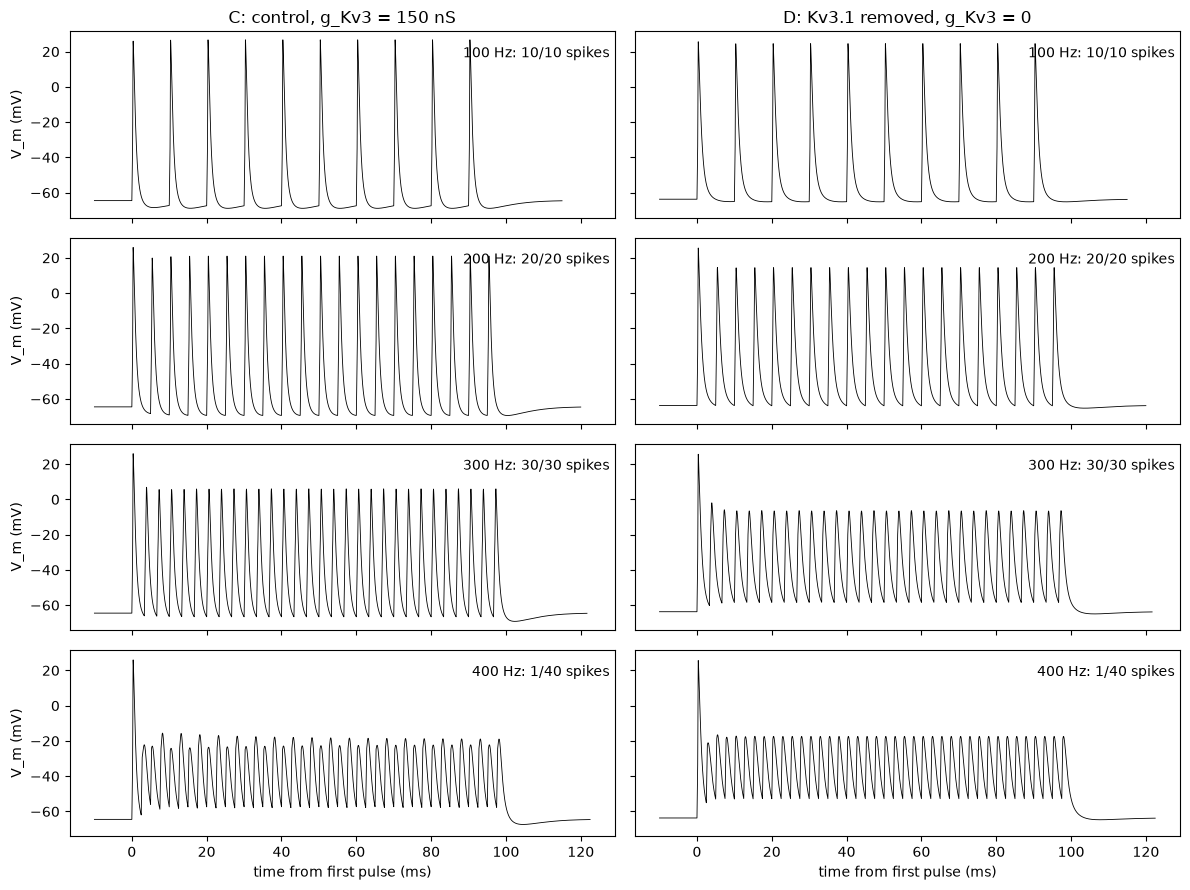

In [6]:
train_ms = 100.        # train length, the same at every frequency
before, after = 10., 25.

fig, axes = plt.subplots(len(freqs), 2, figsize=(12, 9), sharex=True, sharey=True)
for col, (title, g) in enumerate(conditions.items()):
    for row, f in enumerate(freqs):
        n = int(round(train_ms * f / 1000.))
        t, V, n_spikes = pulse_train(f, g, n_pulses=n, t_after=after)
        ax = axes[row, col]
        w = t >= 100 - before
        ax.plot(t[w] - 100, V[w], "k", lw=0.6)
        ax.text(0.99, 0.92, f"{f} Hz: {n_spikes}/{n} spikes", transform=ax.transAxes, ha="right", va="top")
        if row == 0:
            ax.set_title(title)
        if col == 0:
            ax.set_ylabel("V_m (mV)")
for ax in axes[-1]:
    ax.set_xlabel("time from first pulse (ms)")
plt.tight_layout()
plt.show()